In [ ]:
import pandas as pd

df = pd.read_csv("../datasets/df_treino_v3.csv")
df.shape

(3957, 51)

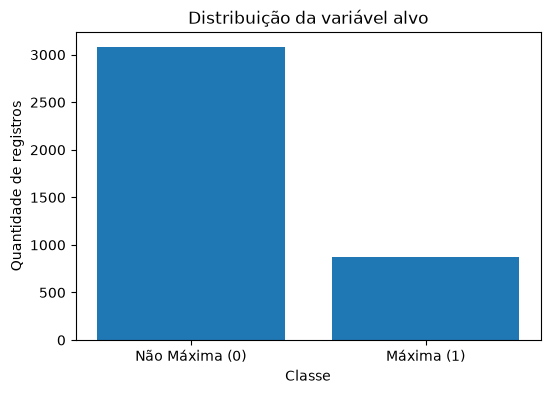

In [2]:
import matplotlib.pyplot as plt

target_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(6,4))
plt.bar(["Não Máxima (0)", "Máxima (1)"], target_counts.values)
plt.title("Distribuição da variável alvo")
plt.ylabel("Quantidade de registros")
plt.xlabel("Classe")
plt.show()

In [5]:
df["target"].value_counts()

target
0    3084
1     873
Name: count, dtype: int64

In [3]:
variaveis_quantitativas = [
    "nome_entrada",
    "desenv_aproximado",
    "desnivel_propeccao"
]

for col in variaveis_quantitativas:
    print("="*80)
    print(col)
    print(df.groupby("target")[col].describe())

nome_entrada
         count      mean       std  min  25%  50%  75%  max
target                                                     
0       3084.0  1.080739  0.344973  1.0  1.0  1.0  1.0  5.0
1        873.0  1.098511  0.379413  1.0  1.0  1.0  1.0  4.0
desenv_aproximado
         count       mean        std  min   25%   50%   75%     max
target                                                             
0       3084.0  13.589306  15.653646  0.0   5.0   9.0  16.0   174.0
1        873.0  40.663070  70.079023  0.0  10.5  19.7  50.0  1546.0
desnivel_propeccao
         count      mean       std  min  25%  50%  75%    max
target                                                       
0       3084.0  1.867857  2.523020  0.0  0.5  1.0  2.2  37.45
1        873.0  3.424490  5.141853  0.0  0.5  1.5  4.0  38.20


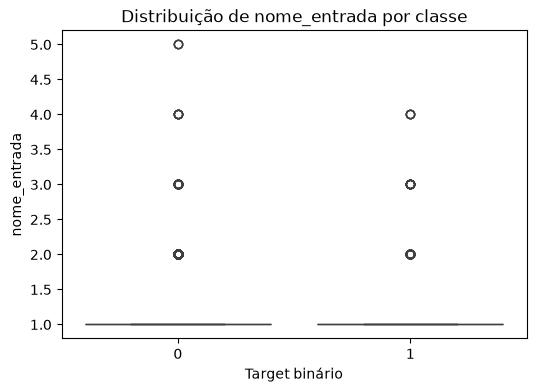

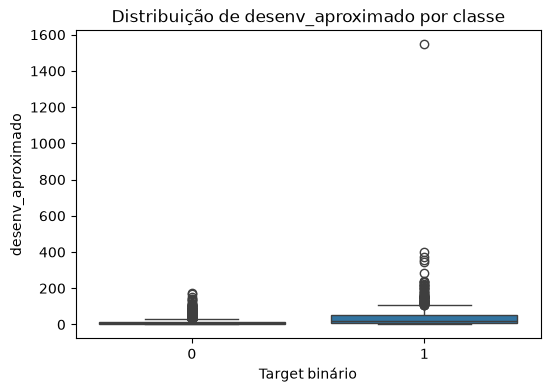

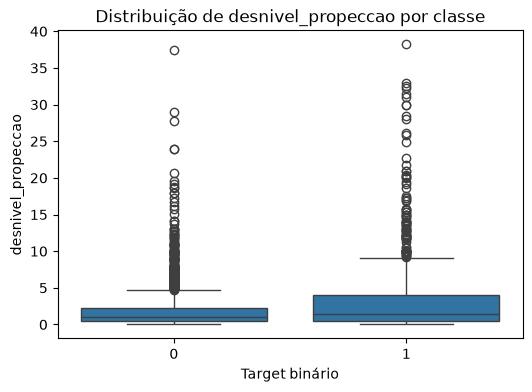

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in variaveis_quantitativas:
    plt.figure(figsize=(6,4))
    sns.boxplot(
        data=df,
        x="target",
        y=col
    )
    plt.title(f"Distribuição de {col} por classe")
    plt.xlabel("Target binário")
    plt.ylabel(col)
    plt.show()


In [6]:
target = "target"

features = df.drop(columns=[target])

colunas_binarias = [
    col for col in features.columns
    if set(features[col].dropna().unique()).issubset({0, 1})
]

print("Quantidade de colunas binárias:", len(colunas_binarias))

for coluna in colunas_binarias:
    print(coluna)


Quantidade de colunas binárias: 46
zona_afotica
raizes
animal_observado_anfibios
animal_observado_aves
animal_observado_invertebrados
animal_observado_mamiferos
animal_observado_morcegos
animal_observado_ninhos
animal_observado_peixes
animal_observado_repteis
tipo_espeleotema_coraloides
tipo_espeleotema_crosta
tipo_espeleotema_escorrimentos
tipo_espeleotema_estalactites
tipo_espeleotema_estalagmites
tipo_espeleotema_pingente
tipo_espeleotema_travertinos
feicao_hidrologica_cachoeira
feicao_hidrologica_condensacao
feicao_hidrologica_drenagem
feicao_hidrologica_gotejamento
feicao_hidrologica_lago
feicao_hidrologica_percolacao
dificuldade_interna_blocos instaveis
dificuldade_interna_lances verticais
dificuldade_interna_quebra-corpo
dificuldade_interna_rastejamento
dificuldade_interna_teto baixo
feicao_interna_blocos abatidos
feicao_interna_canaliculos
feicao_interna_claraboias
feicao_interna_conduto
arqueologia_paleontologia_ceramico
arqueologia_paleontologia_litico
arqueologia_paleontolog

In [14]:
import pandas as pd
import plotly.express as px
grupos = {
    "Animais": [
        "animal_observado_anfibios",
        "animal_observado_aves",
        "animal_observado_invertebrados",
        "animal_observado_mamiferos",
        "animal_observado_morcegos",
        "animal_observado_ninhos",
        "animal_observado_peixes",
        "animal_observado_repteis"
    ],

    "Espeleotemas": [
        "tipo_espeleotema_coraloides",
        "tipo_espeleotema_crosta",
        "tipo_espeleotema_escorrimentos",
        "tipo_espeleotema_estalactites",
        "tipo_espeleotema_estalagmites",
        "tipo_espeleotema_pingente",
        "tipo_espeleotema_travertinos"
    ],

    "Feições Hidrológicas": [
        "feicao_hidrologica_cachoeira",
        "feicao_hidrologica_condensacao",
        "feicao_hidrologica_drenagem",
        "feicao_hidrologica_gotejamento",
        "feicao_hidrologica_lago",
        "feicao_hidrologica_percolacao"
    ],

    "Dificuldades Internas": [
        "dificuldade_interna_blocos instaveis",
        "dificuldade_interna_lances verticais",
        "dificuldade_interna_quebra-corpo",
        "dificuldade_interna_rastejamento",
        "dificuldade_interna_teto baixo"
    ],

    "Feições Internas": [
        "feicao_interna_blocos abatidos",
        "feicao_interna_canaliculos",
        "feicao_interna_claraboias",
        "feicao_interna_conduto",
    ],

    "Arqueologia/Paleontologia": [
        "arqueologia_paleontologia_ceramico",
        "arqueologia_paleontologia_litico",
        "arqueologia_paleontologia_ossada",
        "arqueologia_paleontologia_vestigio historico"
    ],

    "Litotipo": [
        "litotipo_prospeccao_granito-gnaisse",
        "litotipo_prospeccao_rochas carbonaticas",
        "litotipo_prospeccao_rochas ferriferas",
        "litotipo_prospeccao_rochas peliticas",
        "litotipo_prospeccao_rochas siliciosas"
    ],

    "Guano": [
        "ocorrencia_guano_concentrado",
        "ocorrencia_guano_disperso",
    ],

    "Tipo Cavidade": [
        "tipo_cavidade__abrigo",
        "tipo_cavidade__cavidade",
        "tipo_cavidade__feicao espeleologica",
    ]
}
for nome_grupo, colunas in grupos.items():

    resultado = []

    for coluna in colunas:

        subset = df[df[coluna] == 1]

        taxa_maxima = subset["target"].mean() * 100

        quantidade = subset.shape[0]

        resultado.append({
            "categoria": coluna,
            "% maxima": taxa_maxima,
            "quantidade": quantidade
        })

    resultado = pd.DataFrame(resultado)

    resultado = resultado.sort_values(
        "% maxima",
        ascending=False
    )

    fig = px.bar(
        resultado,
        x="% maxima",
        y="categoria",
        orientation="h",
        text="% maxima",
        hover_data=["quantidade"],
        title=f"{nome_grupo} - % de Cavidades Máximas"
    )

    fig.update_traces(
        texttemplate="%{text:.1f}%",
        textposition="outside"
    )

    fig.show()